# ISTG1003 Gruppe 14 - Klyngeanalyse

Klynger av 36 bransje × størrelse-celler etter vekst i KI-bruk 2023–2025.
Metode: k-gjennomsnitt på standardiserte endringar i prosentpoeng.

In [32]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

try:
    from adjustText import adjust_text
    HAS_ADJUST = True
except ImportError:
    HAS_ADJUST = False

INFILE = "SSB_AI_2023-2025.csv"
OUTDIR = Path("bilder")
OUTDIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
K_RANGE = range(2, 7)       # prøvar k = 2, 3, 4, 5, 6
FORCE_K = None              # set til t.d. 3 for å overstyre silhuettvalet

In [33]:
## 1. Last og rydd data

In [34]:
df = pd.read_csv(INFILE, encoding="utf-8-sig")  # -sig fjernar BOM i "year"
df["year"] = df["year"].astype(int)
df["ai_any"] = pd.to_numeric(df["ai_any"], errors="coerce")

INDUSTRY_SHORT = {
    "10-39 Industri":              "Ind.",
    "41-43 Byggje":                "Bygg",
    "45 Handel med og reparasjon": "Mot.",
    "46 Agentur":                  "Engros",
    "47 Detaljhandel":             "Detalj",
    "49-53 Transport":             "Transp.",
    "55-56 Overnattings":          "Over.",
    "58-63 Informasjon":           "IKT",
    "68-75+77-82+95.1 Anna":       "Tjen.",
}

def short_industry(name):
    for prefix, code in INDUSTRY_SHORT.items():
        if name.startswith(prefix):
            return code
    return name[:6]

def short_size(name):
    name = name.strip()
    if name.startswith("10-19"): return "10-19"
    if name.startswith("20-49"): return "20-49"
    if name.startswith("50-99"): return "50-99"
    if name.startswith("100"):   return "100+"
    return name

df.head()

,year,industry,size,industry_classification,source_table,ai_any,text_mining,speech_recognition,text_generation,image_audio_generation,image_recognition,machine_learning,workflow_automation,autonomous_machines
0,2023,"10-39 Industri, kraftforsyning, vatn, avløp og...",10-19 sysselsette,SN2007,13265,5,2,0,1,NaN,1,1,1,1
1,2023,"10-39 Industri, kraftforsyning, vatn, avløp og...",20-49 sysselsette,SN2007,13265,8,1,1,1,NaN,1,3,3,3
2,2023,"10-39 Industri, kraftforsyning, vatn, avløp og...",50-99 sysselsette,SN2007,13265,12,3,0,1,NaN,2,6,6,3
3,2023,"10-39 Industri, kraftforsyning, vatn, avløp og...",100 sysselsette eller fleire,SN2007,13265,28,6,3,2,NaN,9,17,14,9
4,2023,41-43 Byggje- og anleggsverksemd,10-19 sysselsette,SN2007,13265,4,4,1,1,NaN,0,0,0,1


In [35]:
## 2. Pivot til éi rad per (bransje, størrelse)


In [36]:
wide = df.pivot_table(
    index=["industry", "size"],
    columns="year",
    values="ai_any",
).reset_index()
wide.columns.name = None

wide["ind_short"]  = wide["industry"].apply(short_industry)
wide["size_short"] = wide["size"].apply(short_size)

for y in (2023, 2024, 2025):
    if y not in wide.columns:
        raise SystemExit(f"Manglar år {y} i pivoterte data.")

n_before = len(wide)
wide = wide.dropna(subset=[2023, 2024, 2025]).copy()
print(f"Droppar {n_before - len(wide)} celler med manglande verdiar.")
print(f"Brukar {len(wide)} celler (9 bransjar x 4 storrelsar = 36).")
wide.head()

Droppar 0 celler med manglande verdiar.
Brukar 36 celler (9 bransjar x 4 storrelsar = 36).


,industry,size,2023,2024,2025,ind_short,size_short
0,"10-39 Industri, kraftforsyning, vatn, avløp og...",10-19 sysselsette,5.0,10.0,18.0,Ind.,10-19
1,"10-39 Industri, kraftforsyning, vatn, avløp og...",100 sysselsette eller fleire,28.0,40.0,60.0,Ind.,100+
2,"10-39 Industri, kraftforsyning, vatn, avløp og...",20-49 sysselsette,8.0,16.0,28.0,Ind.,20-49
3,"10-39 Industri, kraftforsyning, vatn, avløp og...",50-99 sysselsette,12.0,19.0,38.0,Ind.,50-99
4,41-43 Byggje- og anleggsverksemd,10-19 sysselsette,4.0,6.0,14.0,Bygg,10-19


In [37]:
## 3. Vekstvariablar i prosentpoeng

In [38]:
# ai_any er oppgitt i prosent, så endringa er prosentpoeng (pp)
wide["d_2324"] = wide[2024] - wide[2023]
wide["d_2425"] = wide[2025] - wide[2024]

FEATURES = ["d_2324", "d_2425"]
X = wide[FEATURES].to_numpy()
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

wide[["ind_short", "size_short", "d_2324", "d_2425"]].describe().round(2)

,d_2324,d_2425
count,36.00,36.00
mean,12.61,11.56
std,8.17,7.18
min,0.00,-3.00
25%,6.75,7.75
50%,11.50,13.00
75%,17.25,16.00
max,41.00,25.00


In [39]:
## 4. Vel k — albue og silhuett

Valt k = 5 (silhuett-topp: 5).


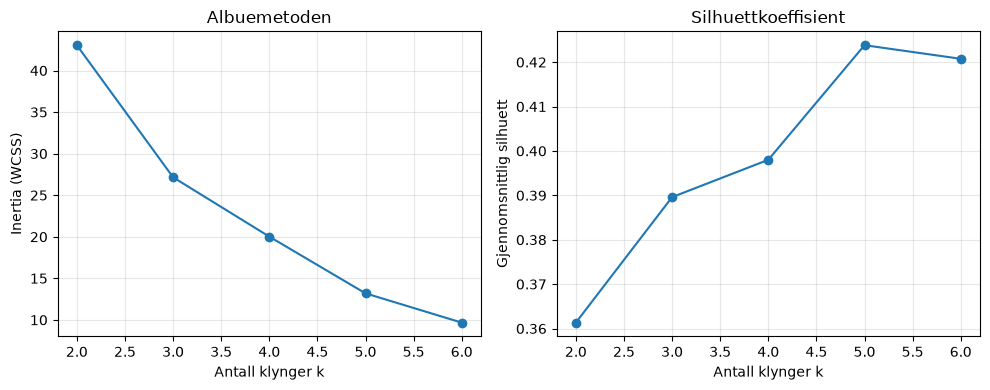

In [40]:
inertias, sils = [], []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_std)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_std, labels))

k_by_sil = list(K_RANGE)[int(np.argmax(sils))]
K = FORCE_K if FORCE_K is not None else k_by_sil
print(f"Valt k = {K} (silhuett-topp: {k_by_sil}).")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(list(K_RANGE), inertias, "o-")
axes[0].set_xlabel("Antall klynger k")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].set_title("Albuemetoden")
axes[0].grid(alpha=0.3)

axes[1].plot(list(K_RANGE), sils, "o-")
axes[1].set_xlabel("Antall klynger k")
axes[1].set_ylabel("Gjennomsnittlig silhuett")
axes[1].set_title("Silhuettkoeffisient")
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTDIR / "klynge_valg.png", dpi=150, bbox_inches="tight")
plt.show()

In [41]:
## 5. Endeleg k-gjennomsnitt-modell

In [42]:
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
wide["cluster"] = km.fit_predict(X_std)
centroids = km.cluster_centers_

wide.groupby("cluster")[["d_2324", "d_2425"]].agg(["mean", "count"]).round(2)

d_2324       d_2425      
          mean count   mean count
cluster                          
0         9.38     8  19.88     8
1         5.50    12   8.17    12
2        30.67     3  17.33     3
3        17.67     9  12.44     9
4        15.50     4  -1.25     4

In [43]:
## 6. Scatter i standardisert rom

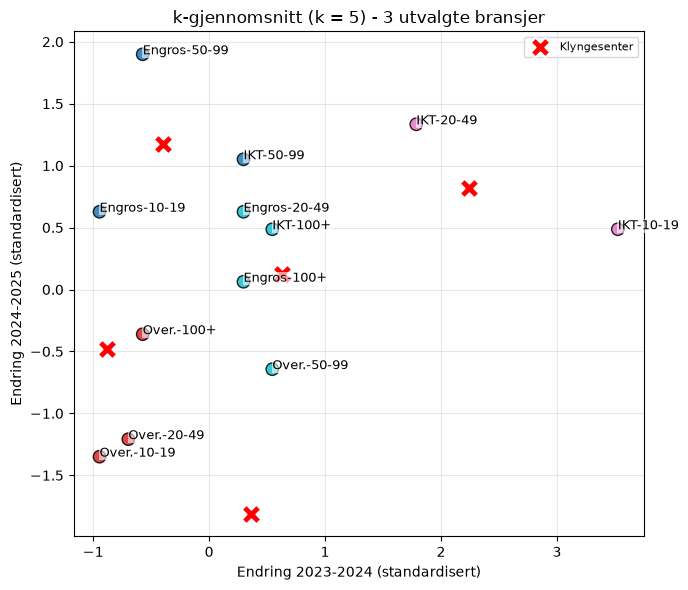

In [51]:
# Opprett ein maske for dei 3 valde bransjane
plot_industries = ["IKT", "Engros", "Over."]
mask = wide["ind_short"].isin(plot_industries)

fig, ax = plt.subplots(figsize=(7, 6))

# Plott berre dei filtrerte punkta (bruk X_std[mask])
ax.scatter(
    X_std[mask, 0], X_std[mask, 1],
    c=wide.loc[mask, "cluster"], cmap="tab10",
    s=80, edgecolor="k", alpha=0.85, zorder=3,
)

# Klyngesentera er rekna ut frå alle 36, men vi viser dei i same plot
ax.scatter(
    centroids[:, 0], centroids[:, 1],
    marker="X", s=200, c="red", edgecolor="white", linewidth=1.5,
    label="Klyngesenter", zorder=4,
)

texts = []
# Legg til tekst berre for dei filtrerte punkta
for i in wide[mask].index:
    label = f"{wide.loc[i, 'ind_short']}-{wide.loc[i, 'size_short']}"
    texts.append(ax.text(X_std[i, 0], X_std[i, 1], label, fontsize=9, zorder=5))

if HAS_ADJUST:
    adjust_text(texts, ax=ax)
else:
    for t in texts:
        t.set_bbox(dict(facecolor="white", alpha=0.6, edgecolor="none", pad=0.4))

ax.set_xlabel("Endring 2023-2024 (standardisert)")
ax.set_ylabel("Endring 2024-2025 (standardisert)")
ax.set_title(f"k-gjennomsnitt (k = {K}) - 3 utvalgte bransjer")
ax.grid(alpha=0.3)
ax.legend(loc="best", fontsize=8)

fig.tight_layout()
fig.savefig(OUTDIR / "klynge_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In [45]:
## 7. Vekstbaner per klynge

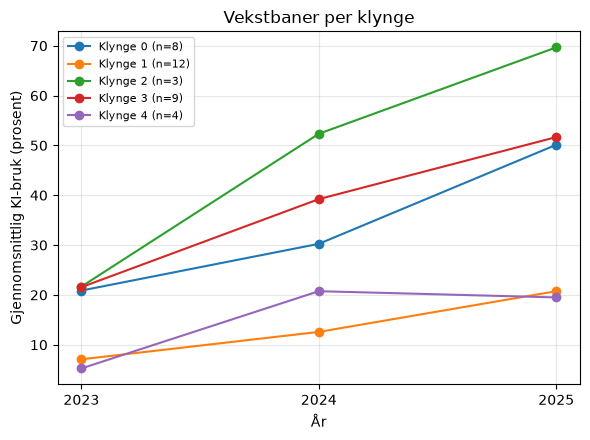

In [46]:
fig, ax = plt.subplots(figsize=(6, 4.5))
cmap = plt.get_cmap("tab10")
for c in sorted(wide["cluster"].unique()):
    sub = wide[wide["cluster"] == c]
    means = [sub[2023].mean(), sub[2024].mean(), sub[2025].mean()]
    ax.plot(
        [2023, 2024, 2025], means,
        marker="o", color=cmap(c),
        label=f"Klynge {c} (n={len(sub)})",
    )

ax.set_xticks([2023, 2024, 2025])
ax.set_xlabel("År")
ax.set_ylabel("Gjennomsnittlig KI-bruk (prosent)")
ax.set_title("Vekstbaner per klynge")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

fig.tight_layout()
fig.savefig(OUTDIR / "klynge_trajektorier.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
## 8. Kryss-tabellar (til `tab:klyngetab`)

In [48]:
ind_order  = [short_industry(x) for x in wide["industry"].unique()]
size_order = ["10-19", "20-49", "50-99", "100+"]

ct_ind  = pd.crosstab(wide["cluster"], wide["ind_short"]).reindex(columns=ind_order)
ct_size = pd.crosstab(wide["cluster"], wide["size_short"]).reindex(columns=size_order)

print("Klynge vs bransje:\n", ct_ind.to_string(), sep="")
print("\nKlynge vs storrelse:\n", ct_size.to_string(), sep="")

ct_ind.to_csv(OUTDIR / "klynge_bransje.csv")
ct_size.to_csv(OUTDIR / "klynge_storrelse.csv")
wide[["industry", "size", 2023, 2024, 2025, "d_2324", "d_2425", "cluster"]] \
    .to_csv(OUTDIR / "klynge_tilhorighet.csv", index=False)

print(f"\nFerdig. Figurar og tabellar ligg i {OUTDIR.resolve()}/")

Klynge vs bransje:
ind_short  Ind.  Bygg  Mot.  Engros  Detalj  Transp.  Over.  IKT  Tjen.
cluster                                                                
0             2     1     0       2       1        1      0    1      0
1             2     2     1       0       1        3      3    0      0
2             0     1     0       0       0        0      0    2      0
3             0     0     1       2       0        0      1    1      4
4             0     0     2       0       2        0      0    0      0

Klynge vs storrelse:
size_short  10-19  20-49  50-99  100+
cluster                              
0               1      0      4     3
1               5      4      2     1
2               1      1      0     1
3               1      2      2     4
4               1      2      1     0

Ferdig. Figurar og tabellar ligg i /home/james/Nedlastinger/Prosjekt/bilder/
